In [ ]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from utils import config

# Указываем устройство
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Теперь все константы вызываются через config.
print("Длина капчи:", config.SEQ_LEN)
print("Количество классов:", config.NUM_CLASSES)

# Получаем абсолютный путь к папке utils и добавляем её в систему поиска Python
utils_path = os.path.abspath('utils')
if utils_path not in sys.path:
    sys.path.append(utils_path)

Using device: cpu
Длина капчи: 5
Количество классов: 36


In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from utils.model import model

# Запускаем обучение
if __name__ == '__main__':
    main()

Используемое устройство: CPU
Старт процесса обучения...
------------------------------------------------------------
Epoch 01/20 | Train Loss: 3.1177 CER: 0.9257 | Val Loss: 2.9522 CER: 0.9262 Acc: 7.38%
 => Сохранена лучшая модель (Best CER: 0.9262)
Epoch 02/20 | Train Loss: 2.9334 CER: 0.9063 | Val Loss: 2.9479 CER: 0.9196 Acc: 8.04%
 => Сохранена лучшая модель (Best CER: 0.9196)
Epoch 03/20 | Train Loss: 2.7994 CER: 0.8743 | Val Loss: 3.3552 CER: 0.9477 Acc: 5.23%
Epoch 04/20 | Train Loss: 2.6076 CER: 0.8493 | Val Loss: 2.9069 CER: 0.9047 Acc: 9.53%
 => Сохранена лучшая модель (Best CER: 0.9047)
Epoch 05/20 | Train Loss: 2.3487 CER: 0.7773 | Val Loss: 2.3775 CER: 0.7991 Acc: 20.09%
 => Сохранена лучшая модель (Best CER: 0.7991)
Epoch 06/20 | Train Loss: 1.9979 CER: 0.7126 | Val Loss: 2.0130 CER: 0.7299 Acc: 27.01%
 => Сохранена лучшая модель (Best CER: 0.7299)
Epoch 07/20 | Train Loss: 1.7120 CER: 0.6371 | Val Loss: 2.0528 CER: 0.7458 Acc: 25.42%
Epoch 08/20 | Train Loss: 1.4410 CER

# СТАТИСТИЧЕСКИЙ АНАЛИЗ ОШИБОК МОДЕЛИ

In [ ]:
from utils import show_worst_predictions, full_statistical_analysis
from utils.dataset import test_loader 
# Собираем ошибки и показываем топ-5 худших предсказаний
errors_data = show_worst_predictions(model, test_loader, top_n=5)
# Запускаем полный статистический анализ
full_statistical_analysis(errors_data)

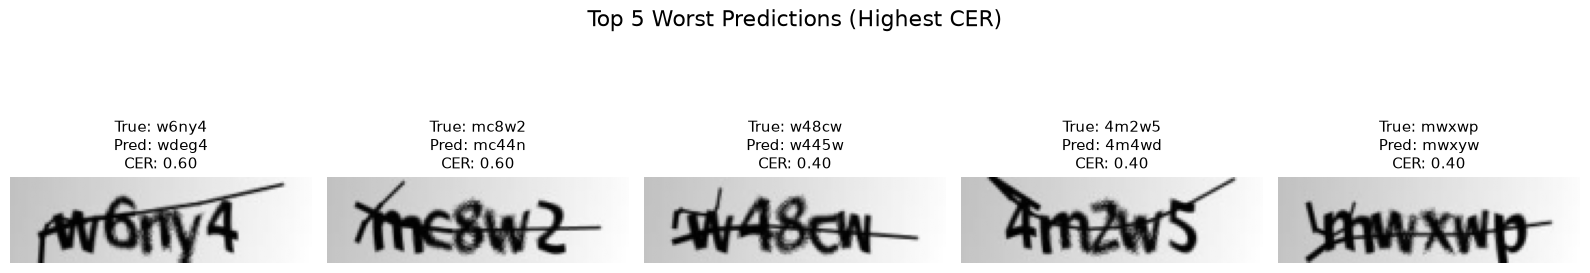

In [ ]:
import os 
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from utils import config
from utils.model import model, device
from utils.dataset import test_loader 
# Функция для расчета CER (доля неверно угаданных символов на позициях)
def calculate_cer(pred, target):
    valid_mask = (target != -100)
    if valid_mask.sum() == 0:
        return 0.0
    incorrect = (pred[valid_mask] != target[valid_mask]).sum().item()
    return incorrect / valid_mask.sum().item()

# Загружаем сохраненные веса
if os.path.exists('weights/best_model.pth'):
    model.load_state_dict(torch.load('weights/best_model.pth', map_location=device))
else:
    print("Внимание: Файл best_model.pth не найден в корне. Используются текущие веса модели.")

model.eval()

errors_data = []
criterion_none = nn.CrossEntropyLoss(reduction='none', ignore_index=-100)

with torch.no_grad():
    for imgs, targets in test_loader:
        imgs, targets = imgs.to(device), targets.to(device)
        logits = model(imgs)
        
        # Считаем лосс для каждого символа отдельно. Форма логитов: (B, 5, 36) -> переводим в (B, 36, 5)
        losses = criterion_none(logits.permute(0, 2, 1), targets)
        img_losses = losses.mean(dim=1) # Средний лосс на картинку
        
        preds = logits.argmax(dim=2)
        
        for i in range(imgs.size(0)):
            # Передаем по одной строке для расчета CER
            cer = calculate_cer(preds[i], targets[i])
            errors_data.append({
                'img': imgs[i].cpu(),
                'true': targets[i].cpu(),
                'pred': preds[i].cpu(),
                'cer': cer,
                'loss': img_losses[i].item()
            })

# Сортируем: сначала по максимальному CER (худшие), затем по Loss
errors_data.sort(key=lambda x: (-x['cer'], -x['loss']))

# Визуализация Топ-5 худших предсказаний
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
fig.suptitle('Top 5 Worst Predictions (Highest CER)', fontsize=16)

for i, ax in enumerate(axes):
    if i >= len(errors_data):
        ax.axis('off')
        continue
        
    data = errors_data[i]
    img = data['img'].squeeze(0).numpy()
    
    # Декодируем тензоры обратно в текстовые строки, используя IDX2CHAR из конфига
    true_str = "".join([config.IDX2CHAR[idx.item()] for idx in data['true'] if idx.item() != -100])
    pred_str = "".join([config.IDX2CHAR[idx.item()] for idx in data['pred']])
    
    # Инвертируем нормализацию обратно в [0, 1] для корректного отображения imshow
    img = (img * 0.5) + 0.5
    
    ax.imshow(img, cmap='gray')
    ax.set_title(f"True: {true_str}\nPred: {pred_str}\nCER: {data['cer']:.2f}", fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
print("\n" + "="*60)
print(" СТАТИСТИЧЕСКИЙ АНАЛИЗ ОШИБОК МОДЕЛИ ")
print("="*60)

# Считаем общую статистику
total_errors = sum(1 for x in errors_data if x['cer'] > 0)
print(f"Всего картинок в тесте с ошибками: {total_errors} из {len(errors_data)}")

print("\nДетальный разбор ТОП-5 худших предсказаний:")
print("-" * 50)
for i in range(min(5, len(errors_data))):
    data = errors_data[i]
    true_str = "".join([config.IDX2CHAR[idx.item()] for idx in data['true'] if idx.item() != -100])
    pred_str = "".join([config.IDX2CHAR[idx.item()] for idx in data['pred']])
    print(f"Пример {i+1} | Истинный текст: '{true_str}' | Предсказано: '{pred_str}' | CER: {data['cer']:.2f} | Loss: {data['loss']:.4f}")

# Сбор статистики: какие символы чаще всего путаются
misclassified_chars = {}
with torch.no_grad():
    for data in errors_data:
        if data['cer'] > 0:
            for t, p in zip(data['true'], data['pred']):
                if t.item() != -100 and t.item() != p.item():
                    char_t = config.IDX2CHAR[t.item()]
                    char_p = config.IDX2CHAR[p.item()]
                    pair = f"'{char_t}' перепутан с '{char_p}'"
                    misclassified_chars[pair] = misclassified_chars.get(pair, 0) + 1

# Вывод топ-3 самых частых сбоев
sorted_pairs = sorted(misclassified_chars.items(), key=lambda x: -x[1])
print("\nСамые частые ошибки посимвольно (Топ-3 пары):")
print("-" * 50)
for pair, count in sorted_pairs[:3]:
    print(f"Пара: {pair} — встретилась {count} раз(а)")



 СТАТИСТИЧЕСКИЙ АНАЛИЗ ОШИБОК МОДЕЛИ 
Всего картинок в тесте с ошибками: 48 из 214

Детальный разбор ТОП-5 худших предсказаний:
--------------------------------------------------
Пример 1 | Истинный текст: 'w6ny4' | Предсказано: 'wdeg4' | CER: 0.60 | Loss: 3.5038
Пример 2 | Истинный текст: 'mc8w2' | Предсказано: 'mc44n' | CER: 0.60 | Loss: 2.9643
Пример 3 | Истинный текст: 'w48cw' | Предсказано: 'w445w' | CER: 0.40 | Loss: 3.1534
Пример 4 | Истинный текст: '4m2w5' | Предсказано: '4m4wd' | CER: 0.40 | Loss: 2.9815
Пример 5 | Истинный текст: 'mwxwp' | Предсказано: 'mwxyw' | CER: 0.40 | Loss: 2.7889

Самые частые ошибки посимвольно (Топ-3 пары):
--------------------------------------------------
Пара: 'm' перепутан с 'n' — встретилась 13 раз(а)
Пара: '5' перепутан с '3' — встретилась 4 раз(а)
Пара: 'y' перепутан с 'g' — встретилась 3 раз(а)


In [8]:
from collections import Counter

print("\n" + "="*60)
print(" ГЛУБОКИЙ АНАЛИТИЧЕСКИЙ РАЗБОР ")
print("="*60)

# 1. Анализ распределения ошибок по позициям в капче
position_errors = [0] * config.SEQ_LEN
total_errors_counted = 0

# Сбор пар замещений
confusion_pairs = []

for data in errors_data:
    if data['cer'] > 0:
        for pos, (t, p) in enumerate(zip(data['true'], data['pred'])):
            if t.item() != -100 and t.item() != p.item():
                position_errors[pos] += 1
                total_errors_counted += 1
                
                char_t = config.IDX2CHAR[t.item()]
                char_p = config.IDX2CHAR[p.item()]
                confusion_pairs.append((char_t, char_p))

print("1. Распределение ошибок по позициям в тексте (1-5 символы):")
for pos, count in enumerate(position_errors):
    percentage = (count / total_errors_counted * 100) if total_errors_counted > 0 else 0
    print(f"   Позиция {pos+1}: {count} ошиб(ок) ({percentage:.1f}%)")

# 2. Топ-5 пар путаницы (Confusion Pairs)
print("\n2. Матрица путаницы — Топ-5 пар частых замещений:")
pair_counts = Counter(confusion_pairs)
for (true_c, pred_c), count in pair_counts.most_common(5):
    print(f"   Истинный символ '{true_c}' -> ошибочно предсказан как '{pred_c}': {count} раз(а)")



 ГЛУБОКИЙ АНАЛИТИЧЕСКИЙ РАЗБОР 
1. Распределение ошибок по позициям в тексте (1-5 символы):
   Позиция 1: 3 ошиб(ок) (4.3%)
   Позиция 2: 10 ошиб(ок) (14.3%)
   Позиция 3: 23 ошиб(ок) (32.9%)
   Позиция 4: 20 ошиб(ок) (28.6%)
   Позиция 5: 14 ошиб(ок) (20.0%)

2. Матрица путаницы — Топ-5 пар частых замещений:
   Истинный символ 'm' -> ошибочно предсказан как 'n': 13 раз(а)
   Истинный символ '5' -> ошибочно предсказан как '3': 4 раз(а)
   Истинный символ 'y' -> ошибочно предсказан как 'g': 3 раз(а)
   Истинный символ 'g' -> ошибочно предсказан как 'y': 3 раз(а)
   Истинный символ 'm' -> ошибочно предсказан как 'w': 3 раз(а)
